In [1]:

# ==================================================
# CELL 1 - IMPORT LIBRARY DAN KONFIGURASI
# FINAL MODEL EVALUATION
# ==================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Direktori proyek
BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "models"

print("FINAL MODEL EVALUATION")
print("=" * 45)
print("Direktori proyek:", BASE_DIR)
print("Direktori output:", OUTPUT_DIR)

assert OUTPUT_DIR.exists(), (
    "Folder outputs tidak ditemukan!"
)

print("\nKonfigurasi berhasil!")


FINAL MODEL EVALUATION
Direktori proyek: d:\python\sem 5\Pemrosesan sinyal\Tugas Besar
Direktori output: d:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs

Konfigurasi berhasil!


In [2]:

# ==================================================
# CELL 2 - INVENTARISASI HASIL MODEL
# ==================================================

# Cari file CSV hasil eksperimen
csv_files = sorted(
    OUTPUT_DIR.rglob("*.csv")
)

# Cari model yang sudah disimpan
model_files = sorted(
    OUTPUT_DIR.rglob("*.joblib")
)

print("DAFTAR FILE CSV")
print("=" * 45)

csv_inventory = pd.DataFrame({
    "Filename": [f.name for f in csv_files],
    "Relative Path": [
        str(f.relative_to(BASE_DIR))
        for f in csv_files
    ],
    "Size (KB)": [
        round(f.stat().st_size / 1024, 2)
        for f in csv_files
    ]
})

display(csv_inventory)

print("\nDAFTAR MODEL TERSIMPAN")
print("=" * 45)

model_inventory = pd.DataFrame({
    "Filename": [f.name for f in model_files],
    "Relative Path": [
        str(f.relative_to(BASE_DIR))
        for f in model_files
    ]
})

display(model_inventory)

print("\nJumlah CSV:", len(csv_files))
print("Jumlah model:", len(model_files))


DAFTAR FILE CSV


,Filename,Relative Path,Size (KB)
0,bearing_clean.csv,outputs\bearing_clean.csv,344245.15
1,bearing_features.csv,outputs\bearing_features.csv,1352.98
2,bearing_features_harmonic.csv,outputs\bearing_features_harmonic.csv,36.74
3,bearing_features_motor_load.csv,outputs\bearing_features_motor_load.csv,36.60
4,bearing_filtered.csv,outputs\bearing_filtered.csv,433005.38
5,harmonic_rf_ablation_study.csv,outputs\harmonic_rf_ablation_study.csv,0.36
6,harmonic_rf_cross_validation.csv,outputs\harmonic_rf_cross_validation.csv,0.29
7,harmonic_rf_feature_importance.csv,outputs\harmonic_rf_feature_importance.csv,0.26
8,harmonic_rf_model_summary.csv,outputs\harmonic_rf_model_summary.csv,0.21
9,harmonic_rf_recording_results.csv,outputs\harmonic_rf_recording_results.csv,0.26



DAFTAR MODEL TERSIMPAN


,Filename,Relative Path
0,random_forest_condition.joblib,outputs\models\random_forest_condition.joblib
1,random_forest_harmonic_motor_load.joblib,outputs\models\random_forest_harmonic_motor_lo...
2,random_forest_motor_load.joblib,outputs\models\random_forest_motor_load.joblib
3,svm_motor_load.joblib,outputs\models\svm_motor_load.joblib
4,xgboost_defect_size.joblib,outputs\models\xgboost_defect_size.joblib



Jumlah CSV: 21
Jumlah model: 5


In [3]:

# ==================================================
# CELL 3 - LOAD HASIL OUTCOME 3
# ==================================================

outcome_3_files = {
    "Model Summary": "harmonic_rf_model_summary.csv",
    "Cross Validation": "harmonic_rf_cross_validation.csv",
    "Feature Importance": "harmonic_rf_feature_importance.csv",
    "Ablation Study": "harmonic_rf_ablation_study.csv",
    "Recording Results": "harmonic_rf_recording_results.csv"
}

outcome_3_results = {}

for name, filename in outcome_3_files.items():

    file_path = OUTPUT_DIR / filename

    if file_path.exists():

        outcome_3_results[name] = pd.read_csv(
            file_path
        )

        print(f"[OK] {name}: {filename}")

    else:
        print(f"[BELUM ADA] {name}: {filename}")

print("\nRINGKASAN OUTCOME 3")
print("=" * 45)

if "Model Summary" in outcome_3_results:
    display(outcome_3_results["Model Summary"])

if "Cross Validation" in outcome_3_results:
    display(outcome_3_results["Cross Validation"])


[OK] Model Summary: harmonic_rf_model_summary.csv
[OK] Cross Validation: harmonic_rf_cross_validation.csv
[OK] Feature Importance: harmonic_rf_feature_importance.csv
[OK] Ablation Study: harmonic_rf_ablation_study.csv
[OK] Recording Results: harmonic_rf_recording_results.csv

RINGKASAN OUTCOME 3


,Evaluation,Accuracy,Macro F1
0,Training,0.966102,0.968214
1,Testing,0.990000,0.987492
2,Cross-Validation (Segment),0.971974,0.971096
3,Cross-Validation (Recording),1.000000,1.000000


,Fold,Train Recordings,Validation Recordings,Segment Accuracy,Segment Macro F1,Recording Accuracy,Recording Macro F1
0,1,30,10,0.970000,0.969400,1.0,1.0
1,2,30,10,0.980000,0.983315,1.0,1.0
2,3,30,10,0.980000,0.977448,1.0,1.0
3,4,30,10,0.957895,0.954220,1.0,1.0


In [4]:

# ==================================================
# CELL 4 - LOAD HASIL OUTCOME 1 DAN OUTCOME 2
# ==================================================

evaluation_files = {
    "Outcome 1 - Cross Validation":
        "rf_cross_validation.csv",

    "Outcome 1 - Feature Importance":
        "rf_feature_importance.csv",

    "Outcome 2 - Predictions":
        "xgb_defect_predictions.csv",

    "Outcome 2 - Feature Importance":
        "xgb_feature_importance.csv",

    "Outcome 3 - Model Summary":
        "harmonic_rf_model_summary.csv",

    "Outcome 3 - Cross Validation":
        "harmonic_rf_cross_validation.csv"
}

evaluation_data = {}

for name, filename in evaluation_files.items():

    path = OUTPUT_DIR / filename

    if path.exists():
        evaluation_data[name] = pd.read_csv(path)

        print(f"\n{'=' * 55}")
        print(name)
        print(f"File: {filename}")
        print(f"Jumlah baris: {len(evaluation_data[name])}")
        print("Kolom:", evaluation_data[name].columns.tolist())

        display(evaluation_data[name].head())

    else:
        print(f"\n[FILE TIDAK DITEMUKAN] {filename}")



Outcome 1 - Cross Validation
File: rf_cross_validation.csv
Jumlah baris: 4
Kolom: ['Fold', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Test Recordings']


,Fold,Accuracy,Precision,Recall,F1-Score,Test Recordings
0,1,0.996047,0.996743,0.996711,0.996705,10
1,2,0.901980,0.930227,0.918317,0.918871,10
2,3,0.891667,0.923154,0.772391,0.801130,10
3,4,0.949555,0.959835,0.957970,0.957913,10



Outcome 1 - Feature Importance
File: rf_feature_importance.csv
Jumlah baris: 16
Kolom: ['Feature', 'Importance']


,Feature,Importance
0,peak_to_peak,0.191100
1,peak_amplitude,0.121768
2,std,0.118824
3,band_power_mid,0.113525
4,rms,0.113229



Outcome 2 - Predictions
File: xgb_defect_predictions.csv
Jumlah baris: 909
Kolom: ['Actual', 'Predicted', 'Absolute Error']


,Actual,Predicted,Absolute Error
0,0.007,0.007551,0.000551
1,0.007,0.007769,0.000769
2,0.007,0.007680,0.000680
3,0.007,0.007807,0.000807
4,0.007,0.006926,0.000074


... (2 outputs left out)


Outcome 3 - Model Summary
File: harmonic_rf_model_summary.csv
Jumlah baris: 4
Kolom: ['Evaluation', 'Accuracy', 'Macro F1']


,Evaluation,Accuracy,Macro F1
0,Training,0.966102,0.968214
1,Testing,0.990000,0.987492
2,Cross-Validation (Segment),0.971974,0.971096
3,Cross-Validation (Recording),1.000000,1.000000



Outcome 3 - Cross Validation
File: harmonic_rf_cross_validation.csv
Jumlah baris: 4
Kolom: ['Fold', 'Train Recordings', 'Validation Recordings', 'Segment Accuracy', 'Segment Macro F1', 'Recording Accuracy', 'Recording Macro F1']


,Fold,Train Recordings,Validation Recordings,Segment Accuracy,Segment Macro F1,Recording Accuracy,Recording Macro F1
0,1,30,10,0.970000,0.969400,1.0,1.0
1,2,30,10,0.980000,0.983315,1.0,1.0
2,3,30,10,0.980000,0.977448,1.0,1.0
3,4,30,10,0.957895,0.954220,1.0,1.0


In [5]:

# ==================================================
# CELL 5 - PEMERIKSAAN KELENGKAPAN EVALUASI
# ==================================================

required_results = {
    "Outcome 1": [
        "rf_cross_validation.csv",
        "rf_feature_importance.csv"
    ],
    "Outcome 2": [
        "xgb_defect_predictions.csv",
        "xgb_feature_importance.csv"
    ],
    "Outcome 3": [
        "harmonic_rf_model_summary.csv",
        "harmonic_rf_cross_validation.csv",
        "harmonic_rf_ablation_study.csv",
        "harmonic_rf_recording_results.csv"
    ]
}

check_results = []

for outcome, filenames in required_results.items():
    for filename in filenames:

        exists = (OUTPUT_DIR / filename).exists()

        check_results.append({
            "Outcome": outcome,
            "File": filename,
            "Status": "Tersedia" if exists else "Belum Ada"
        })

check_df = pd.DataFrame(check_results)

print("PEMERIKSAAN KELENGKAPAN EVALUASI")
display(check_df)

print("\nJumlah file tersedia:",
      (check_df["Status"] == "Tersedia").sum())

print("Jumlah file belum ada:",
      (check_df["Status"] == "Belum Ada").sum())


PEMERIKSAAN KELENGKAPAN EVALUASI


,Outcome,File,Status
0,Outcome 1,rf_cross_validation.csv,Tersedia
1,Outcome 1,rf_feature_importance.csv,Tersedia
2,Outcome 2,xgb_defect_predictions.csv,Tersedia
3,Outcome 2,xgb_feature_importance.csv,Tersedia
4,Outcome 3,harmonic_rf_model_summary.csv,Tersedia
5,Outcome 3,harmonic_rf_cross_validation.csv,Tersedia
6,Outcome 3,harmonic_rf_ablation_study.csv,Tersedia
7,Outcome 3,harmonic_rf_recording_results.csv,Tersedia



Jumlah file tersedia: 8
Jumlah file belum ada: 0


In [6]:

# ==================================================
# CELL 6 - REKAPITULASI EVALUASI KETIGA OUTCOME
# ==================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------
# OUTCOME 1 - RANDOM FOREST CLASSIFICATION
# ------------------------------------------

rf_cv = pd.read_csv(
    OUTPUT_DIR / "rf_cross_validation.csv"
)

print("OUTCOME 1 - RANDOM FOREST")
print("Kolom tersedia:", rf_cv.columns.tolist())
display(rf_cv.head())

# ------------------------------------------
# OUTCOME 2 - XGBOOST REGRESSION
# ------------------------------------------

xgb_predictions = pd.read_csv(
    OUTPUT_DIR / "xgb_defect_predictions.csv"
)

print("\nOUTCOME 2 - XGBOOST")
print("Kolom tersedia:", xgb_predictions.columns.tolist())
display(xgb_predictions.head())

# ------------------------------------------
# OUTCOME 3 - RANDOM FOREST HARMONIC
# ------------------------------------------

harmonic_cv = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_cross_validation.csv"
)

print("\nOUTCOME 3 - RANDOM FOREST HARMONIC")
print("Kolom tersedia:", harmonic_cv.columns.tolist())
display(harmonic_cv.head())

# ------------------------------------------
# SIMPAN REFERENSI DATA EVALUASI
# ------------------------------------------

evaluation_sources = {
    "Outcome 1": rf_cv,
    "Outcome 2": xgb_predictions,
    "Outcome 3": harmonic_cv
}

print("\nSeluruh sumber evaluasi berhasil dimuat!")


OUTCOME 1 - RANDOM FOREST
Kolom tersedia: ['Fold', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Test Recordings']


,Fold,Accuracy,Precision,Recall,F1-Score,Test Recordings
0,1,0.996047,0.996743,0.996711,0.996705,10
1,2,0.901980,0.930227,0.918317,0.918871,10
2,3,0.891667,0.923154,0.772391,0.801130,10
3,4,0.949555,0.959835,0.957970,0.957913,10



OUTCOME 2 - XGBOOST
Kolom tersedia: ['Actual', 'Predicted', 'Absolute Error']


,Actual,Predicted,Absolute Error
0,0.007,0.007551,0.000551
1,0.007,0.007769,0.000769
2,0.007,0.007680,0.000680
3,0.007,0.007807,0.000807
4,0.007,0.006926,0.000074



OUTCOME 3 - RANDOM FOREST HARMONIC
Kolom tersedia: ['Fold', 'Train Recordings', 'Validation Recordings', 'Segment Accuracy', 'Segment Macro F1', 'Recording Accuracy', 'Recording Macro F1']


,Fold,Train Recordings,Validation Recordings,Segment Accuracy,Segment Macro F1,Recording Accuracy,Recording Macro F1
0,1,30,10,0.970000,0.969400,1.0,1.0
1,2,30,10,0.980000,0.983315,1.0,1.0
2,3,30,10,0.980000,0.977448,1.0,1.0
3,4,30,10,0.957895,0.954220,1.0,1.0



Seluruh sumber evaluasi berhasil dimuat!


In [7]:

# ==================================================
# CELL 7 - REKAPITULASI EVALUASI FINAL
# ==================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# OUTCOME 1 - RANDOM FOREST
outcome_1_summary = pd.DataFrame([{
    "Outcome": "Bearing Condition",
    "Model": "Random Forest",
    "Accuracy": rf_cv["Accuracy"].mean(),
    "Precision": rf_cv["Precision"].mean(),
    "Recall": rf_cv["Recall"].mean(),
    "F1-Score": rf_cv["F1-Score"].mean()
}])

# OUTCOME 2 - XGBOOST REGRESSION
y_actual = xgb_predictions["Actual"]
y_predicted = xgb_predictions["Predicted"]

outcome_2_summary = pd.DataFrame([{
    "Outcome": "Defect Size",
    "Model": "XGBoost Regression",
    "MAE": mean_absolute_error(
        y_actual, y_predicted
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_actual, y_predicted
        )
    ),
    "R2": r2_score(
        y_actual, y_predicted
    )
}])

# OUTCOME 3 - RANDOM FOREST HARMONIC
outcome_3_summary = pd.DataFrame([{
    "Outcome": "Motor Load",
    "Model": "Random Forest Harmonic",
    "Segment Accuracy":
        harmonic_cv["Segment Accuracy"].mean(),
    "Segment Macro F1":
        harmonic_cv["Segment Macro F1"].mean(),
    "Recording Accuracy":
        harmonic_cv["Recording Accuracy"].mean(),
    "Recording Macro F1":
        harmonic_cv["Recording Macro F1"].mean()
}])

print("OUTCOME 1 - BEARING CONDITION")
display(outcome_1_summary.round(4))

print("\nOUTCOME 2 - DEFECT SIZE")
display(outcome_2_summary.round(6))

print("\nOUTCOME 3 - MOTOR LOAD")
display(outcome_3_summary.round(4))

# Simpan seluruh hasil
outcome_1_summary.to_csv(
    OUTPUT_DIR / "final_outcome_1_summary.csv",
    index=False
)

outcome_2_summary.to_csv(
    OUTPUT_DIR / "final_outcome_2_summary.csv",
    index=False
)

outcome_3_summary.to_csv(
    OUTPUT_DIR / "final_outcome_3_summary.csv",
    index=False
)

print("\nSeluruh ringkasan evaluasi berhasil disimpan!")


OUTCOME 1 - BEARING CONDITION


,Outcome,Model,Accuracy,Precision,Recall,F1-Score
0,Bearing Condition,Random Forest,0.9348,0.9525,0.9113,0.9187



OUTCOME 2 - DEFECT SIZE


,Outcome,Model,MAE,RMSE,R2
0,Defect Size,XGBoost Regression,0.000648,0.001195,0.956253



OUTCOME 3 - MOTOR LOAD


,Outcome,Model,Segment Accuracy,Segment Macro F1,Recording Accuracy,Recording Macro F1
0,Motor Load,Random Forest Harmonic,0.972,0.9711,1.0,1.0



Seluruh ringkasan evaluasi berhasil disimpan!


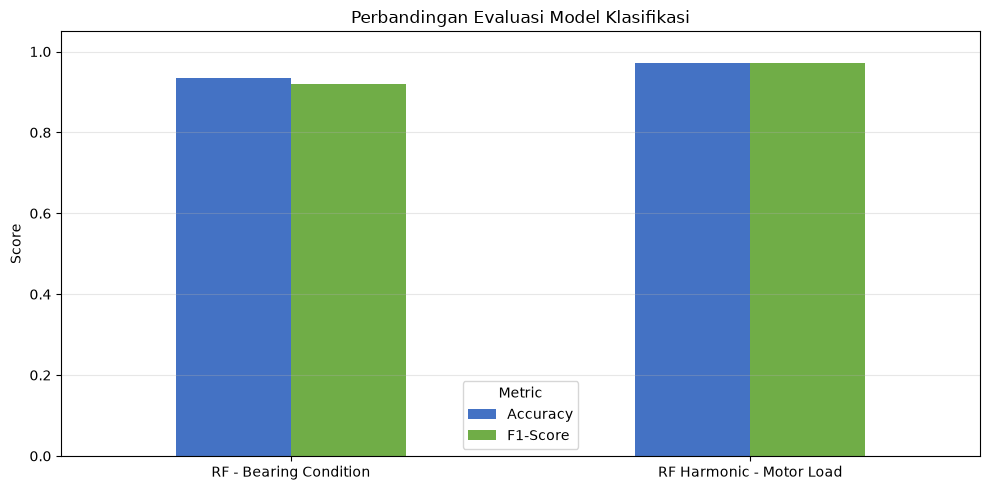

,Model,Accuracy,F1-Score
0,RF - Bearing Condition,0.9348,0.9187
1,RF Harmonic - Motor Load,0.9720,0.9711


In [ ]:

# ==================================================
# CELL 8 - VISUALISASI EVALUASI KLASIFIKASI
# ==================================================
# karena sama sama menggunakan RF

comparison_df = pd.DataFrame({
    "Model": [
        "RF - Bearing Condition",
        "RF Harmonic - Motor Load"
    ],
    "Accuracy": [
        outcome_1_summary["Accuracy"].iloc[0],
        outcome_3_summary["Segment Accuracy"].iloc[0]
    ],
    "F1-Score": [
        outcome_1_summary["F1-Score"].iloc[0],
        outcome_3_summary["Segment Macro F1"].iloc[0]
    ]
})

comparison_plot = comparison_df.set_index("Model")

ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#4472C4", "#70AD47"],
    rot=0
)

ax.set_title(
    "Perbandingan Evaluasi Model Klasifikasi"
)
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)

plt.legend(title="Metric")
plt.tight_layout()
plt.show()

display(comparison_df.round(4))


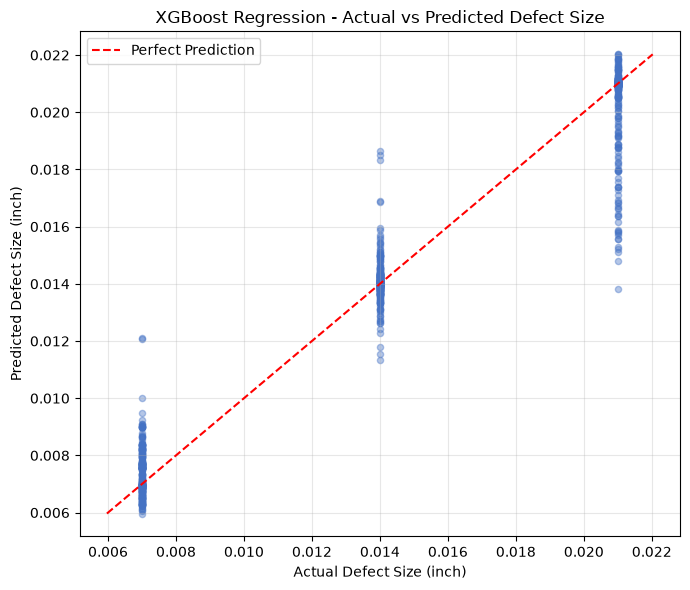

In [9]:

# ==================================================
# CELL 9 - VISUALISASI PREDIKSI XGBOOST
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Menggunakan data prediksi Outcome 2
actual = xgb_predictions["Actual"].to_numpy()
predicted = xgb_predictions["Predicted"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 6))

# Scatter plot aktual vs prediksi
ax.scatter(
    actual,
    predicted,
    alpha=0.4,
    s=20,
    color="#4472C4"
)

# Garis prediksi sempurna
min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

ax.set_title(
    "XGBoost Regression - Actual vs Predicted Defect Size"
)
ax.set_xlabel("Actual Defect Size (inch)")
ax.set_ylabel("Predicted Defect Size (inch)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


ANALISIS ERROR BERDASARKAN UKURAN CACAT


,Actual,Total_Samples,MAE,Median_Error,Max_Error
0,0.007,303,0.000670,0.000570,0.005091
1,0.014,303,0.000439,0.000235,0.004638
2,0.021,303,0.000836,0.000127,0.007180


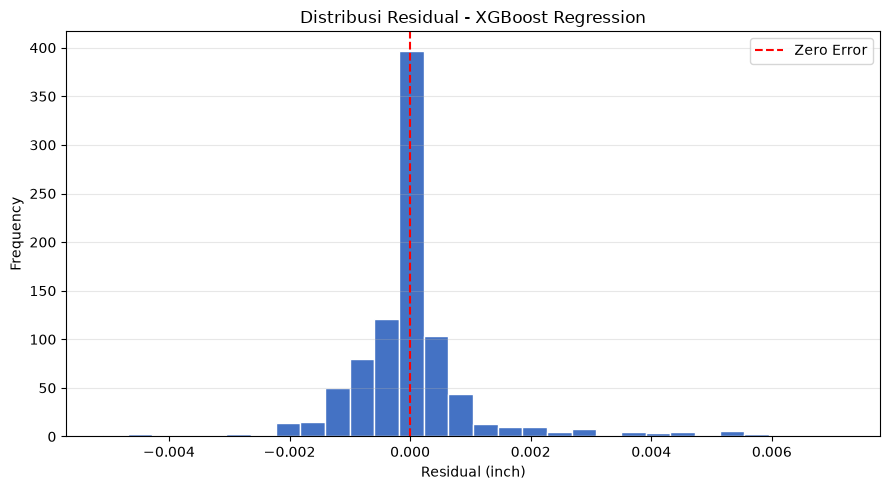

Analisis error XGBoost berhasil disimpan!


In [10]:

# ==================================================
# CELL 10 - ANALISIS ERROR PREDIKSI XGBOOST
# ==================================================

from sklearn.metrics import mean_absolute_error

error_df = xgb_predictions.copy()

# Menghitung residual dan absolute error
error_df["Residual"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute Error"] = (
    error_df["Residual"].abs()
)

# Statistik error berdasarkan ukuran cacat
error_summary = (
    error_df
    .groupby("Actual")
    .agg(
        Total_Samples=("Absolute Error", "count"),
        MAE=("Absolute Error", "mean"),
        Median_Error=("Absolute Error", "median"),
        Max_Error=("Absolute Error", "max")
    )
    .reset_index()
)

print("ANALISIS ERROR BERDASARKAN UKURAN CACAT")
display(error_summary.round(6))

# Visualisasi distribusi residual
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    error_df["Residual"],
    bins=30,
    color="#4472C4",
    edgecolor="white"
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

ax.set_title("Distribusi Residual - XGBoost Regression")
ax.set_xlabel("Residual (inch)")
ax.set_ylabel("Frequency")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Simpan analisis error
error_summary.to_csv(
    OUTPUT_DIR / "final_xgb_error_analysis.csv",
    index=False
)

print("Analisis error XGBoost berhasil disimpan!")


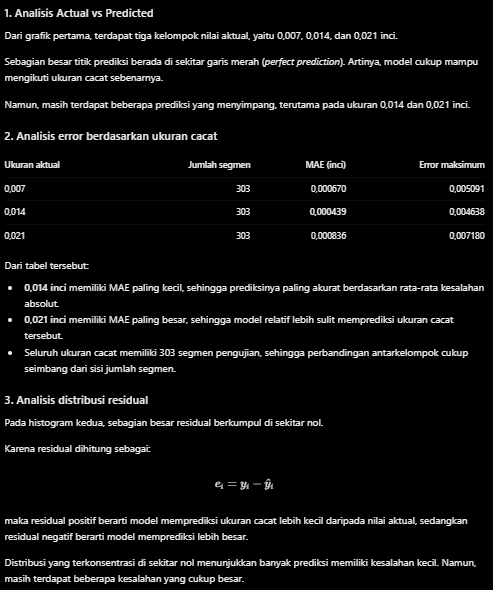

In [11]:

# ==================================================
# CELL 11 - RINGKASAN EVALUASI XGBOOST
# ==================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = xgb_predictions["Actual"]
predicted = xgb_predictions["Predicted"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

# Normalisasi MAE terhadap rentang target
target_range = actual.max() - actual.min()
nmae = mae / target_range if target_range > 0 else np.nan

xgb_final_summary = pd.DataFrame([{
    "Model": "XGBoost Regression",
    "MAE (inch)": mae,
    "RMSE (inch)": rmse,
    "R2": r2,
    "Normalized MAE": nmae,
    "Total Test Segments": len(actual)
}])

print("RINGKASAN EVALUASI XGBOOST")
print("=" * 45)

display(xgb_final_summary.round(6))

xgb_final_summary.to_csv(
    OUTPUT_DIR / "final_xgb_evaluation.csv",
    index=False
)

print("\nRingkasan evaluasi berhasil disimpan!")


RINGKASAN EVALUASI XGBOOST


,Model,MAE (inch),RMSE (inch),R2,Normalized MAE,Total Test Segments
0,XGBoost Regression,0.000648,0.001195,0.956253,0.046319,909



Ringkasan evaluasi berhasil disimpan!


In [12]:

# ==================================================
# CELL 12 - RINGKASAN FINAL KETIGA OUTCOME
# ==================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# OUTCOME 1 - KLASIFIKASI KONDISI BEARING
rf_cv = pd.read_csv(
    OUTPUT_DIR / "rf_cross_validation.csv"
)

# OUTCOME 2 - PREDIKSI UKURAN CACAT
xgb_predictions = pd.read_csv(
    OUTPUT_DIR / "xgb_defect_predictions.csv"
)

# OUTCOME 3 - KLASIFIKASI BEBAN MOTOR
harmonic_cv = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_cross_validation.csv"
)

# Menghitung metrik regresi
actual = xgb_predictions["Actual"]
predicted = xgb_predictions["Predicted"]

xgb_mae = mean_absolute_error(actual, predicted)
xgb_rmse = np.sqrt(mean_squared_error(actual, predicted))
xgb_r2 = r2_score(actual, predicted)

# Tabel ringkasan klasifikasi
classification_summary = pd.DataFrame([
    {
        "Outcome": "1 - Bearing Condition",
        "Model": "Random Forest",
        "Accuracy": rf_cv["Accuracy"].mean(),
        "F1-Score": rf_cv["F1-Score"].mean(),
        "Evaluation": "4-Fold Group CV"
    },
    {
        "Outcome": "3 - Motor Load",
        "Model": "Random Forest Harmonic",
        "Accuracy": harmonic_cv["Segment Accuracy"].mean(),
        "F1-Score": harmonic_cv["Segment Macro F1"].mean(),
        "Evaluation": "4-Fold Group CV"
    }
])

# Tabel ringkasan regresi
regression_summary = pd.DataFrame([{
    "Outcome": "2 - Defect Size",
    "Model": "XGBoost Regression",
    "MAE (inch)": xgb_mae,
    "RMSE (inch)": xgb_rmse,
    "R2": xgb_r2,
    "Total Predictions": len(actual)
}])

print("RINGKASAN FINAL MODEL KLASIFIKASI")
display(classification_summary.round(4))

print("\nRINGKASAN FINAL MODEL REGRESI")
display(regression_summary.round(6))

# Simpan hasil
classification_summary.to_csv(
    OUTPUT_DIR / "final_classification_summary.csv",
    index=False
)

regression_summary.to_csv(
    OUTPUT_DIR / "final_regression_summary.csv",
    index=False
)

print("\nRingkasan final berhasil disimpan!")


RINGKASAN FINAL MODEL KLASIFIKASI


,Outcome,Model,Accuracy,F1-Score,Evaluation
0,1 - Bearing Condition,Random Forest,0.9348,0.9187,4-Fold Group CV
1,3 - Motor Load,Random Forest Harmonic,0.9720,0.9711,4-Fold Group CV



RINGKASAN FINAL MODEL REGRESI


,Outcome,Model,MAE (inch),RMSE (inch),R2,Total Predictions
0,2 - Defect Size,XGBoost Regression,0.000648,0.001195,0.956253,909



Ringkasan final berhasil disimpan!


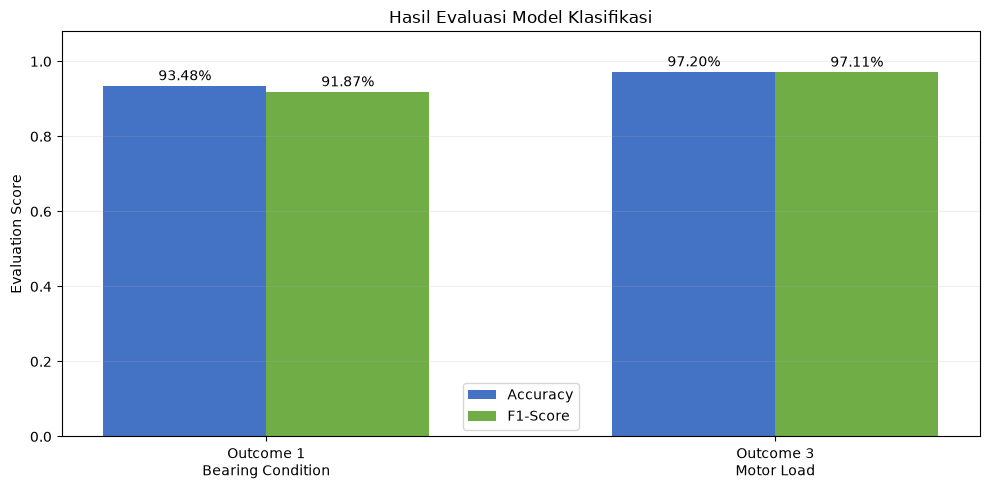

In [13]:

# ==================================================
# CELL 13 - VISUALISASI HASIL AKHIR KLASIFIKASI
# ==================================================

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(classification_summary))
width = 0.32

accuracy_values = classification_summary[
    "Accuracy"
].to_numpy()

f1_values = classification_summary[
    "F1-Score"
].to_numpy()

bars1 = ax.bar(
    x - width / 2,
    accuracy_values,
    width,
    label="Accuracy",
    color="#4472C4"
)

bars2 = ax.bar(
    x + width / 2,
    f1_values,
    width,
    label="F1-Score",
    color="#70AD47"
)

# Label nilai pada setiap batang
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height * 100:.2f}%",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

ax.set_xticks(x)
ax.set_xticklabels([
    "Outcome 1\nBearing Condition",
    "Outcome 3\nMotor Load"
])

ax.set_ylabel("Evaluation Score")
ax.set_title(
    "Hasil Evaluasi Model Klasifikasi"
)
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Simpan gambar
plt.savefig(
    OUTPUT_DIR / "final_classification_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

# ==================================================
# CELL 14 - VALIDASI HASIL AKHIR
# ==================================================

final_files = [
    "final_classification_summary.csv",
    "final_regression_summary.csv",
    "final_xgb_error_analysis.csv",
    "final_classification_comparison.png",
    "harmonic_rf_cross_validation.csv",
    "harmonic_rf_ablation_study.csv"
]

validation_results = pd.DataFrame([
    {
        "File": filename,
        "Status": (
            "Tersedia"
            if (OUTPUT_DIR / filename).exists()
            else "Belum Ada"
        )
    }
    for filename in final_files
])

print("VALIDASI HASIL PENELITIAN")
display(validation_results)

missing_files = validation_results[
    validation_results["Status"] == "Belum Ada"
]

if missing_files.empty:
    print("\nSeluruh file hasil akhir tersedia!")
else:
    print(
        "\nMasih ada",
        len(missing_files),
        "file yang belum tersedia."
    )


VALIDASI HASIL PENELITIAN


,File,Status
0,final_classification_summary.csv,Tersedia
1,final_regression_summary.csv,Tersedia
2,final_xgb_error_analysis.csv,Tersedia
3,final_classification_comparison.png,Tersedia
4,harmonic_rf_cross_validation.csv,Tersedia
5,harmonic_rf_ablation_study.csv,Tersedia



Seluruh file hasil akhir tersedia!


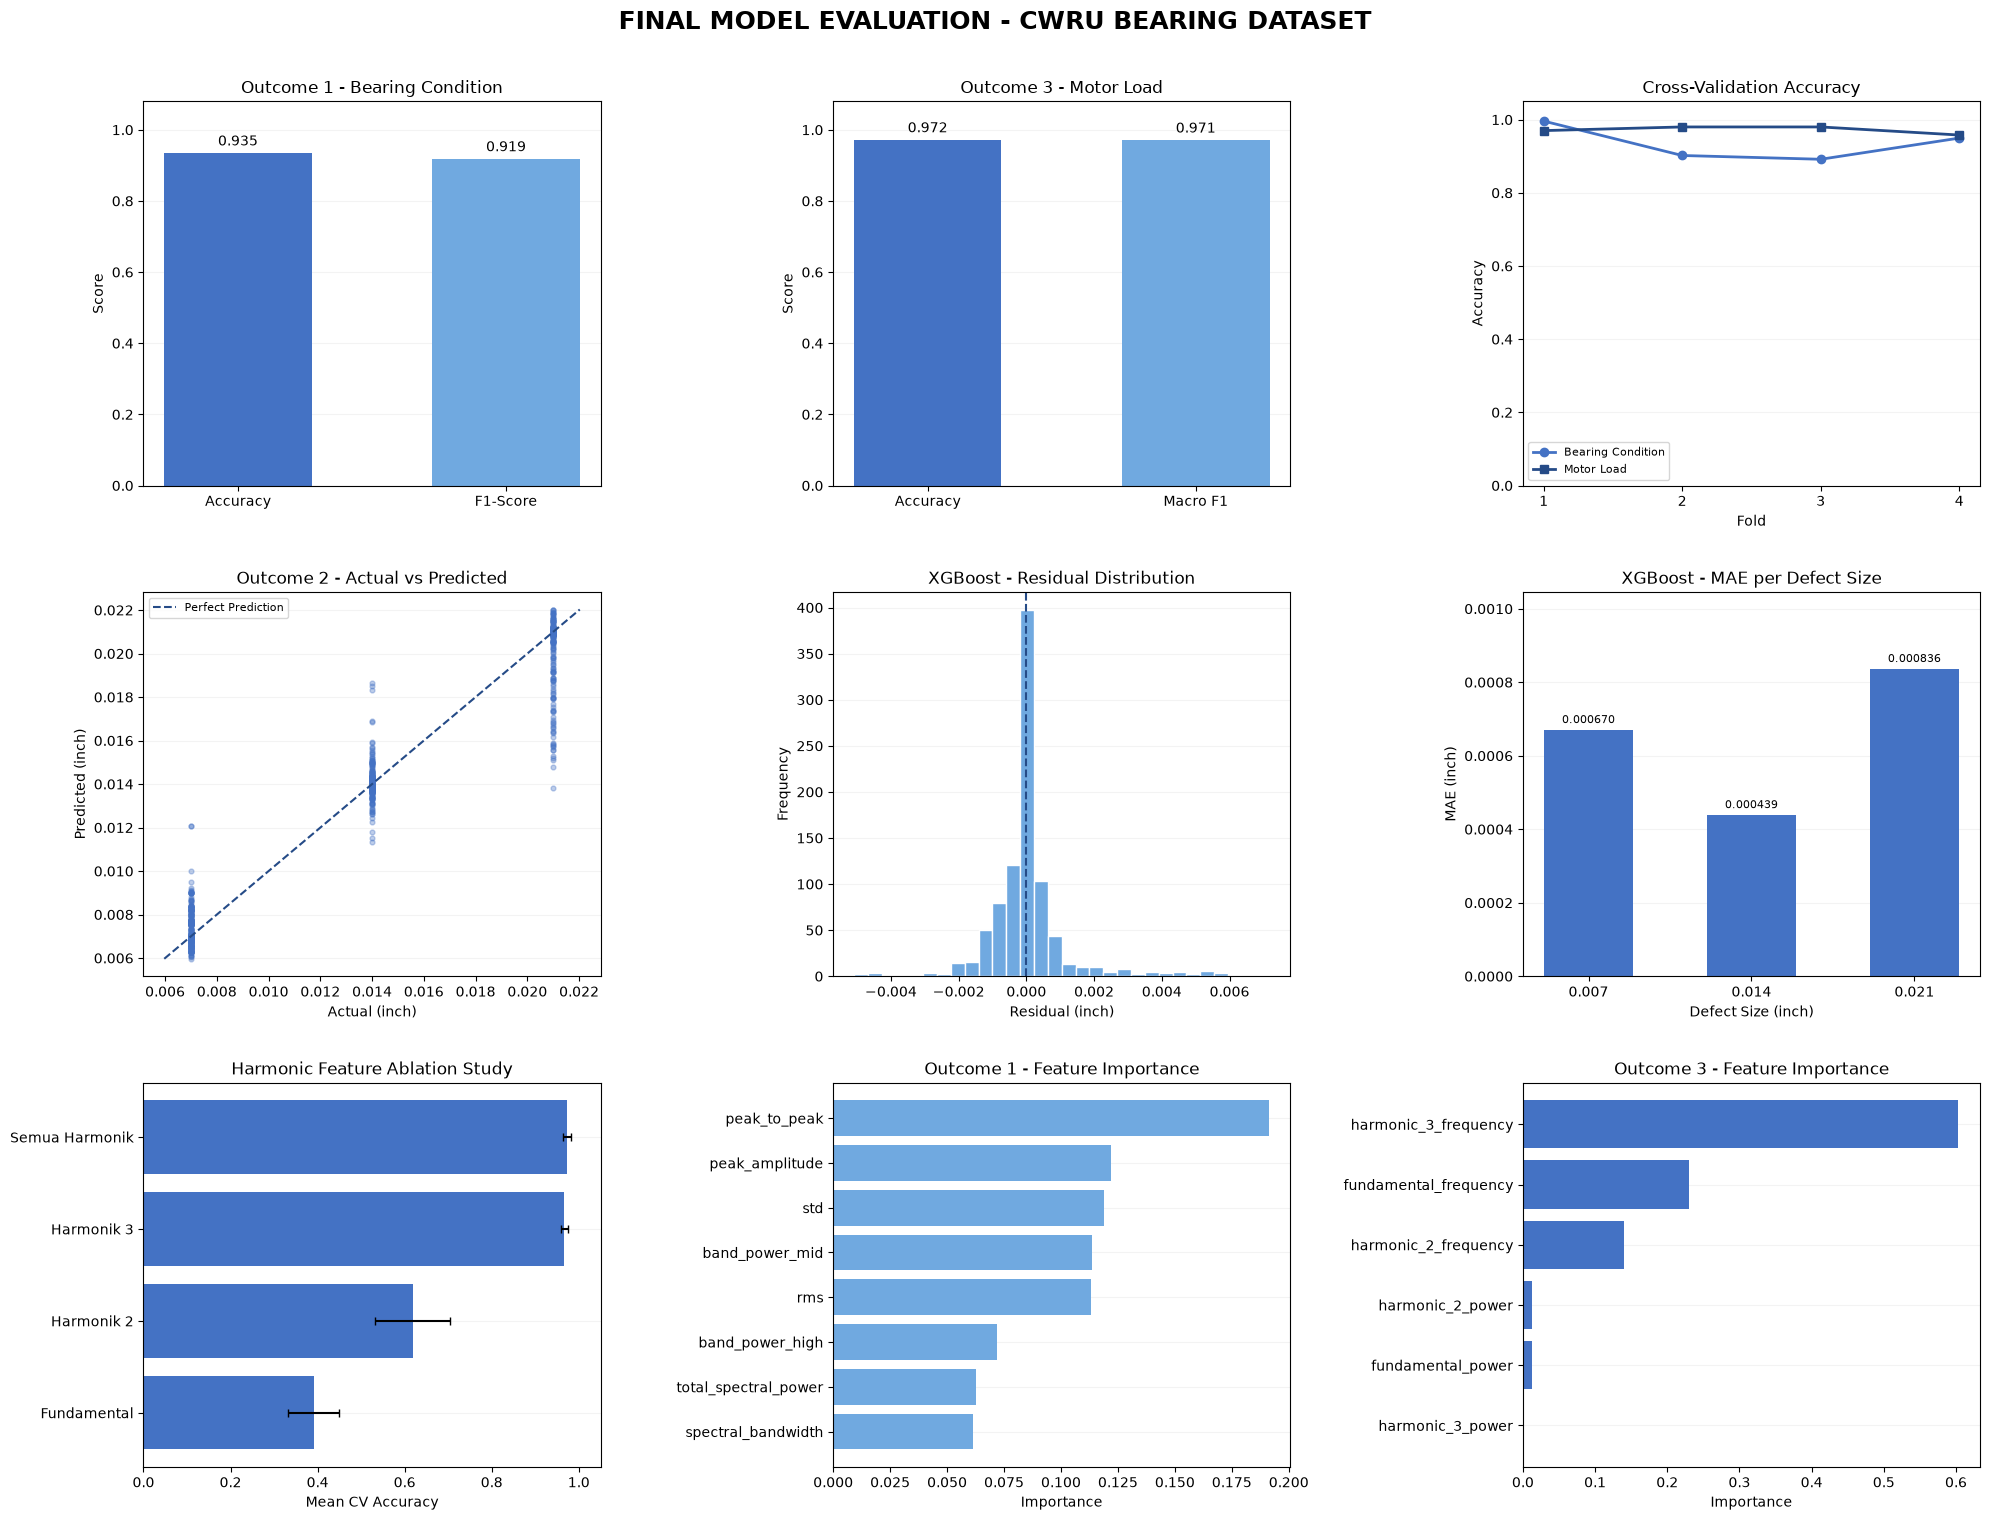

Dashboard berhasil disimpan:
d:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs\final_evaluation_dashboard.png


In [15]:

# ==========================================================
# CELL 15 - DASHBOARD EVALUASI SELURUH OUTCOME
# Layout: 3 Baris x 3 Kolom
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ----------------------------------------------------------
# 1. LOAD DATA EVALUASI
# ----------------------------------------------------------

rf_cv = pd.read_csv(
    OUTPUT_DIR / "rf_cross_validation.csv"
)

harmonic_cv = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_cross_validation.csv"
)

xgb_pred = pd.read_csv(
    OUTPUT_DIR / "xgb_defect_predictions.csv"
)

ablation = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_ablation_study.csv"
)

rf_importance = pd.read_csv(
    OUTPUT_DIR / "rf_feature_importance.csv"
)

harmonic_importance = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_feature_importance.csv"
)

# Normalisasi nama kolom untuk feature importance
def prepare_importance(df):
    df = df.copy()
    df.columns = df.columns.str.strip()

    feature_col = next(
        c for c in df.columns
        if c.lower() in ["feature", "features"]
    )
    importance_col = next(
        c for c in df.columns
        if c.lower() in ["importance", "importance_score"]
    )

    return df.rename(columns={
        feature_col: "Feature",
        importance_col: "Importance"
    }).sort_values("Importance", ascending=False)

rf_importance = prepare_importance(rf_importance)
harmonic_importance = prepare_importance(harmonic_importance)

# ----------------------------------------------------------
# 2. KONFIGURASI VISUALISASI
# ----------------------------------------------------------

BLUE = "#4472C4"
LIGHT_BLUE = "#70A9E0"
DARK_BLUE = "#254B87"
GRAY = "#AAB4C3"

fig, axes = plt.subplots(
    3, 3,
    figsize=(20, 15)
)

fig.patch.set_facecolor("white")

# ----------------------------------------------------------
# GRAFIK 1 - OUTCOME 1 CLASSIFICATION
# ----------------------------------------------------------

ax = axes[0, 0]

metrics_1 = [
    rf_cv["Accuracy"].mean(),
    rf_cv["F1-Score"].mean()
]

bars = ax.bar(
    ["Accuracy", "F1-Score"],
    metrics_1,
    color=[BLUE, LIGHT_BLUE],
    width=0.55
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

ax.set_title("Outcome 1 - Bearing Condition")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)

# ----------------------------------------------------------
# GRAFIK 2 - OUTCOME 3 CLASSIFICATION
# ----------------------------------------------------------

ax = axes[0, 1]

metrics_3 = [
    harmonic_cv["Segment Accuracy"].mean(),
    harmonic_cv["Segment Macro F1"].mean()
]

bars = ax.bar(
    ["Accuracy", "Macro F1"],
    metrics_3,
    color=[BLUE, LIGHT_BLUE],
    width=0.55
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

ax.set_title("Outcome 3 - Motor Load")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)

# ----------------------------------------------------------
# GRAFIK 3 - CROSS-VALIDATION COMPARISON
# ----------------------------------------------------------

ax = axes[0, 2]

folds = np.arange(1, len(rf_cv) + 1)

ax.plot(
    folds,
    rf_cv["Accuracy"],
    marker="o",
    linewidth=2,
    color=BLUE,
    label="Bearing Condition"
)

ax.plot(
    folds,
    harmonic_cv["Segment Accuracy"],
    marker="s",
    linewidth=2,
    color=DARK_BLUE,
    label="Motor Load"
)

ax.set_title("Cross-Validation Accuracy")
ax.set_xlabel("Fold")
ax.set_ylabel("Accuracy")
ax.set_xticks(folds)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)

# ----------------------------------------------------------
# GRAFIK 4 - XGBOOST ACTUAL VS PREDICTED
# ----------------------------------------------------------

ax = axes[1, 0]

actual = xgb_pred["Actual"]
predicted = xgb_pred["Predicted"]

ax.scatter(
    actual,
    predicted,
    alpha=0.35,
    s=12,
    color=BLUE
)

low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

ax.plot(
    [low, high],
    [low, high],
    "--",
    color=DARK_BLUE,
    linewidth=1.5,
    label="Perfect Prediction"
)

ax.set_title("Outcome 2 - Actual vs Predicted")
ax.set_xlabel("Actual (inch)")
ax.set_ylabel("Predicted (inch)")
ax.legend(fontsize=8)

# ----------------------------------------------------------
# GRAFIK 5 - RESIDUAL DISTRIBUTION
# ----------------------------------------------------------

ax = axes[1, 1]

residual = actual - predicted

ax.hist(
    residual,
    bins=30,
    color=LIGHT_BLUE,
    edgecolor="white"
)

ax.axvline(
    0,
    linestyle="--",
    color=DARK_BLUE
)

ax.set_title("XGBoost - Residual Distribution")
ax.set_xlabel("Residual (inch)")
ax.set_ylabel("Frequency")

# ----------------------------------------------------------
# GRAFIK 6 - MAE PER DEFECT SIZE
# ----------------------------------------------------------

ax = axes[1, 2]

error_df = pd.DataFrame({
    "Actual": actual,
    "Absolute_Error": np.abs(residual)
})

mae_group = (
    error_df.groupby("Actual")["Absolute_Error"]
    .mean()
)

bars = ax.bar(
    [f"{v:.3f}" for v in mae_group.index],
    mae_group.values,
    color=BLUE,
    width=0.55
)

ax.bar_label(
    bars,
    fmt="%.6f",
    padding=3,
    fontsize=8
)

ax.set_title("XGBoost - MAE per Defect Size")
ax.set_xlabel("Defect Size (inch)")
ax.set_ylabel("MAE (inch)")
ax.set_ylim(0, mae_group.max() * 1.25)

# ----------------------------------------------------------
# GRAFIK 7 - HARMONIC ABLATION STUDY
# ----------------------------------------------------------

ax = axes[2, 0]

ablation_plot = ablation.sort_values(
    "Mean Accuracy",
    ascending=True
)

ax.barh(
    ablation_plot["Feature Set"],
    ablation_plot["Mean Accuracy"],
    xerr=ablation_plot["Std Accuracy"],
    capsize=3,
    color=BLUE
)

ax.set_title("Harmonic Feature Ablation Study")
ax.set_xlabel("Mean CV Accuracy")
ax.set_xlim(0, 1.05)

# ----------------------------------------------------------
# GRAFIK 8 - FEATURE IMPORTANCE OUTCOME 1
# ----------------------------------------------------------

ax = axes[2, 1]

top_rf = rf_importance.head(8).iloc[::-1]

ax.barh(
    top_rf["Feature"],
    top_rf["Importance"],
    color=LIGHT_BLUE
)

ax.set_title("Outcome 1 - Feature Importance")
ax.set_xlabel("Importance")

# ----------------------------------------------------------
# GRAFIK 9 - FEATURE IMPORTANCE OUTCOME 3
# ----------------------------------------------------------

ax = axes[2, 2]

top_harmonic = harmonic_importance.iloc[::-1]

ax.barh(
    top_harmonic["Feature"],
    top_harmonic["Importance"],
    color=BLUE
)

ax.set_title("Outcome 3 - Feature Importance")
ax.set_xlabel("Importance")

# ----------------------------------------------------------
# 3. FINALISASI DASHBOARD
# ----------------------------------------------------------

for ax in axes.flat:
    ax.grid(
        axis="y",
        alpha=0.15
    )
    ax.set_axisbelow(True)

fig.suptitle(
    "FINAL MODEL EVALUATION - CWRU BEARING DATASET",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout(
    h_pad=3.0,
    w_pad=2.5
)

# Simpan sebagai gambar resolusi tinggi
dashboard_path = (
    OUTPUT_DIR / "final_evaluation_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Dashboard berhasil disimpan:")
print(dashboard_path)


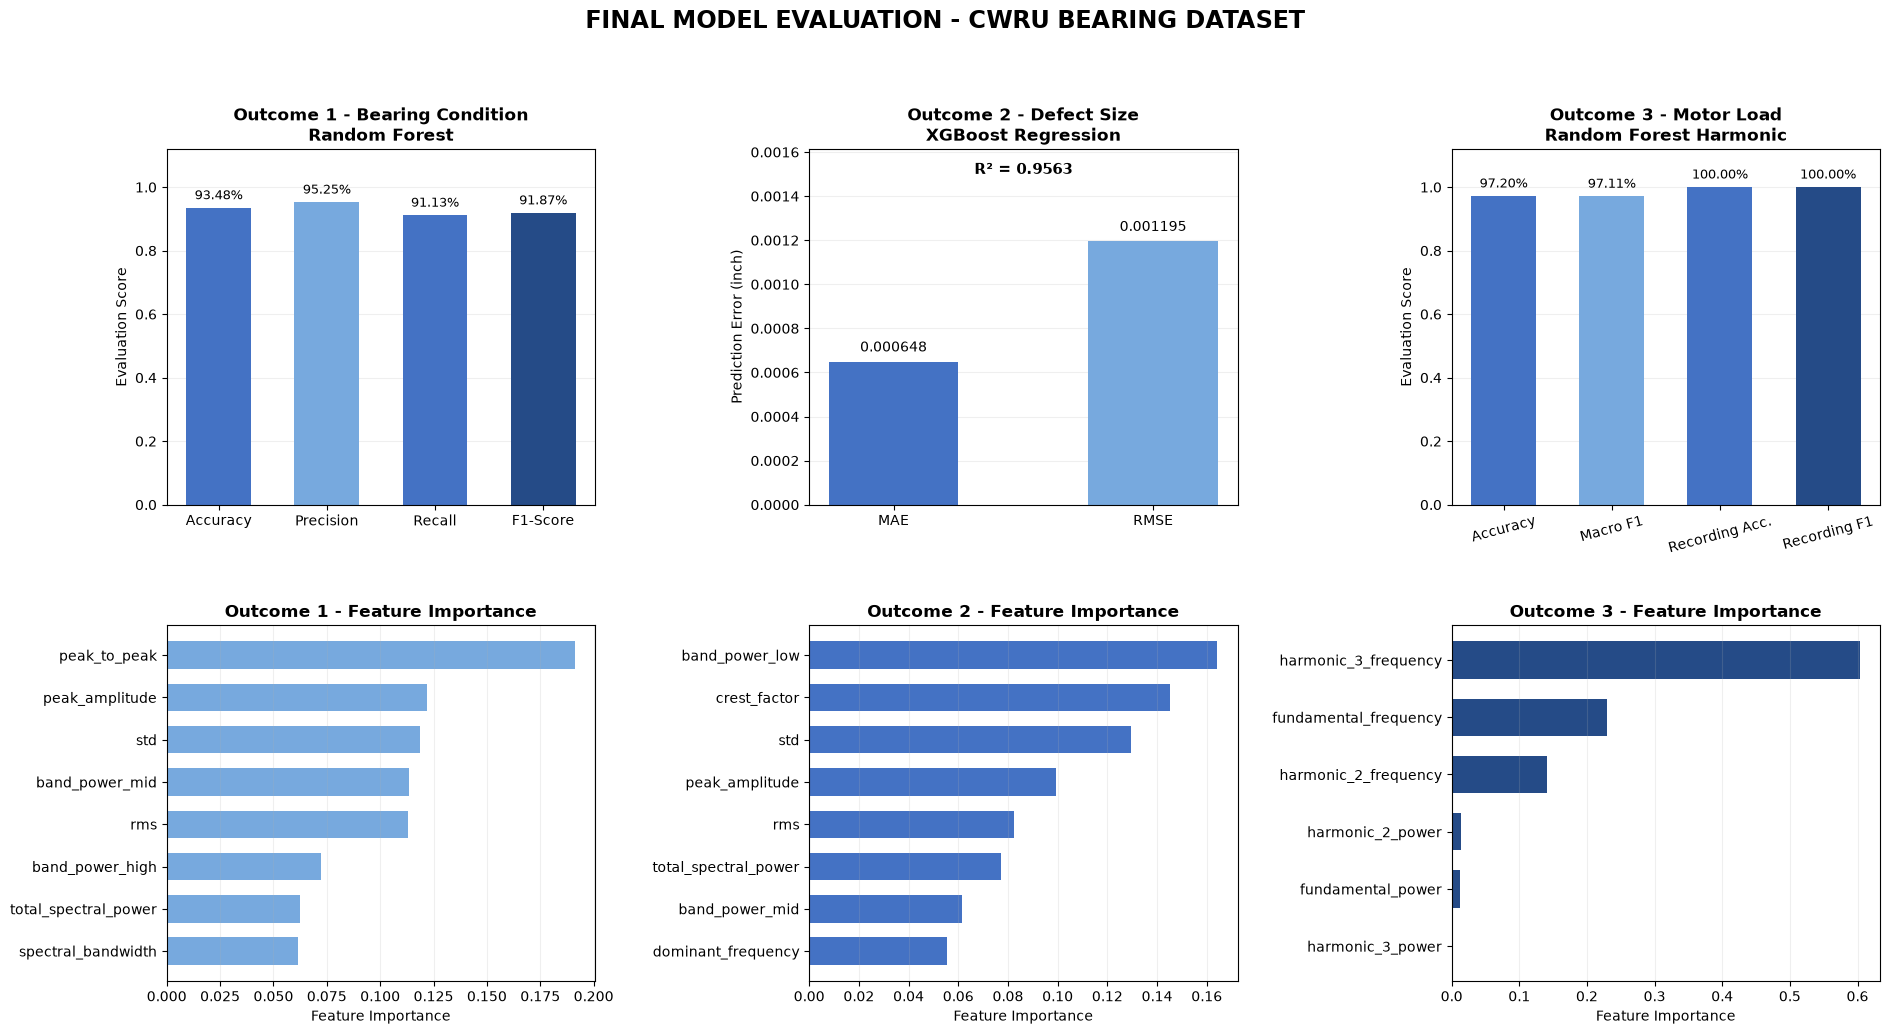

Dashboard berhasil disimpan!
Lokasi: d:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs\final_evaluation_dashboard.png


In [16]:

# ==========================================================
# CELL 15 - FINAL EVALUATION DASHBOARD
# 3 Outcome x 2 Visualisasi
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================================
# 1. LOAD DATA
# ==========================================================

rf_cv = pd.read_csv(
    OUTPUT_DIR / "rf_cross_validation.csv"
)

xgb_pred = pd.read_csv(
    OUTPUT_DIR / "xgb_defect_predictions.csv"
)

harmonic_cv = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_cross_validation.csv"
)

rf_importance = pd.read_csv(
    OUTPUT_DIR / "rf_feature_importance.csv"
)

xgb_importance = pd.read_csv(
    OUTPUT_DIR / "xgb_feature_importance.csv"
)

harmonic_importance = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_feature_importance.csv"
)

# ==========================================================
# 2. NORMALISASI NAMA KOLOM FEATURE IMPORTANCE
# ==========================================================

def prepare_importance(df):
    df = df.copy()
    df.columns = df.columns.str.strip()

    feature_col = next(
        c for c in df.columns
        if c.lower() in ["feature", "features"]
    )

    importance_col = next(
        c for c in df.columns
        if c.lower() in [
            "importance",
            "importance_score",
            "feature_importance",
            "weight",
            "gain"
        ]
    )

    return (
        df.rename(columns={
            feature_col: "Feature",
            importance_col: "Importance"
        })
        .sort_values("Importance", ascending=False)
    )

rf_importance = prepare_importance(rf_importance)
xgb_importance = prepare_importance(xgb_importance)
harmonic_importance = prepare_importance(
    harmonic_importance
)

# ==========================================================
# 3. KONFIGURASI FIGURE
# ==========================================================

BLUE = "#4472C4"
LIGHT_BLUE = "#77A9DE"
DARK_BLUE = "#254B87"

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 10.5)
)

fig.patch.set_facecolor("white")

# ==========================================================
# BARIS 1 - HASIL EVALUASI
# ==========================================================

# ----------------------------------------------------------
# OUTCOME 1 - RANDOM FOREST CONDITION
# ----------------------------------------------------------

ax = axes[0, 0]

metrics_1 = {
    "Accuracy": rf_cv["Accuracy"].mean(),
    "Precision": rf_cv["Precision"].mean(),
    "Recall": rf_cv["Recall"].mean(),
    "F1-Score": rf_cv["F1-Score"].mean()
}

bars = ax.bar(
    list(metrics_1.keys()),
    list(metrics_1.values()),
    color=[BLUE, LIGHT_BLUE, BLUE, DARK_BLUE],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{v * 100:.2f}%"
        for v in metrics_1.values()
    ],
    padding=4,
    fontsize=9
)

ax.set_title(
    "Outcome 1 - Bearing Condition\nRandom Forest",
    fontweight="bold"
)
ax.set_ylabel("Evaluation Score")
ax.set_ylim(0, 1.12)

# ----------------------------------------------------------
# OUTCOME 2 - XGBOOST DEFECT SIZE
# ----------------------------------------------------------

ax = axes[0, 1]

actual = xgb_pred["Actual"]
predicted = xgb_pred["Predicted"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

# MAE dan RMSE menggunakan satuan inci
bars = ax.bar(
    ["MAE", "RMSE"],
    [mae, rmse],
    color=[BLUE, LIGHT_BLUE],
    width=0.5
)

ax.bar_label(
    bars,
    labels=[
        f"{mae:.6f}",
        f"{rmse:.6f}"
    ],
    padding=5,
    fontsize=10
)

ax.set_title(
    "Outcome 2 - Defect Size\nXGBoost Regression",
    fontweight="bold"
)

ax.set_ylabel("Prediction Error (inch)")
ax.set_ylim(0, max(mae, rmse) * 1.35)

# Tampilkan R2 sebagai informasi tambahan
ax.text(
    0.5, 0.93,
    f"R² = {r2:.4f}",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
    fontweight="bold"
)

# ----------------------------------------------------------
# OUTCOME 3 - RANDOM FOREST MOTOR LOAD
# ----------------------------------------------------------

ax = axes[0, 2]

metrics_3 = {
    "Accuracy": harmonic_cv[
        "Segment Accuracy"
    ].mean(),
    "Macro F1": harmonic_cv[
        "Segment Macro F1"
    ].mean(),
    "Recording Acc.": harmonic_cv[
        "Recording Accuracy"
    ].mean(),
    "Recording F1": harmonic_cv[
        "Recording Macro F1"
    ].mean()
}

bars = ax.bar(
    list(metrics_3.keys()),
    list(metrics_3.values()),
    color=[BLUE, LIGHT_BLUE, BLUE, DARK_BLUE],
    width=0.6
)

ax.bar_label(
    bars,
    labels=[
        f"{v * 100:.2f}%"
        for v in metrics_3.values()
    ],
    padding=4,
    fontsize=9
)

ax.set_title(
    "Outcome 3 - Motor Load\nRandom Forest Harmonic",
    fontweight="bold"
)

ax.set_ylabel("Evaluation Score")
ax.set_ylim(0, 1.12)
ax.tick_params(axis="x", labelrotation=15)

# ==========================================================
# BARIS 2 - FEATURE IMPORTANCE
# ==========================================================

importance_data = [
    (
        rf_importance,
        "Outcome 1 - Feature Importance",
        LIGHT_BLUE
    ),
    (
        xgb_importance,
        "Outcome 2 - Feature Importance",
        BLUE
    ),
    (
        harmonic_importance,
        "Outcome 3 - Feature Importance",
        DARK_BLUE
    )
]

for col, (data, title, color) in enumerate(
    importance_data
):

    ax = axes[1, col]

    # Ambil maksimal 8 fitur terpenting
    top_features = (
        data.head(8)
        .iloc[::-1]
    )

    ax.barh(
        top_features["Feature"],
        top_features["Importance"],
        color=color,
        height=0.65
    )

    ax.set_title(
        title,
        fontweight="bold"
    )

    ax.set_xlabel("Feature Importance")

    ax.grid(
        axis="x",
        alpha=0.2
    )

# ==========================================================
# 4. FINALISASI LAYOUT
# ==========================================================

for ax in axes[0, :]:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "FINAL MODEL EVALUATION - CWRU BEARING DATASET",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94],
    h_pad=3.5,
    w_pad=2.5
)

# ==========================================================
# 5. SIMPAN DASHBOARD
# ==========================================================

dashboard_path = (
    OUTPUT_DIR / "final_evaluation_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Dashboard berhasil disimpan!")
print("Lokasi:", dashboard_path)


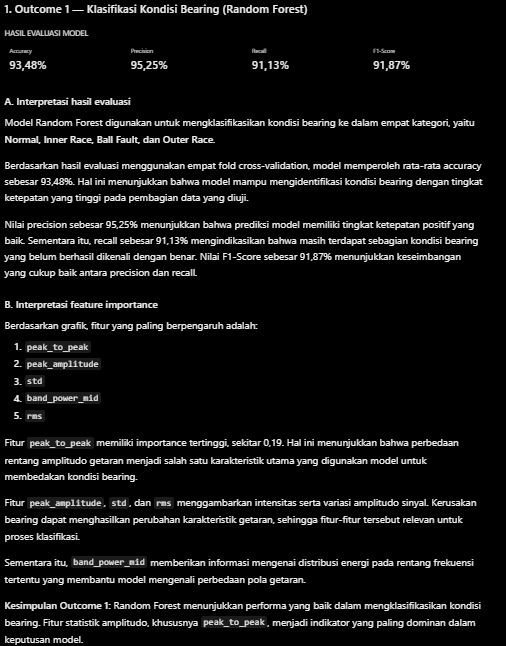

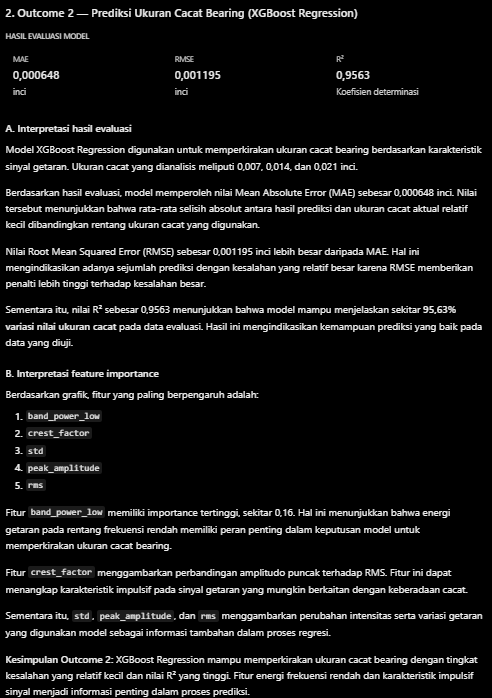

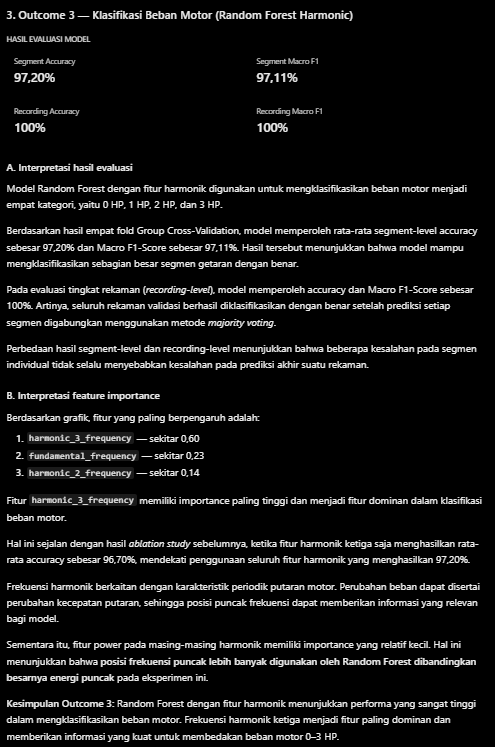

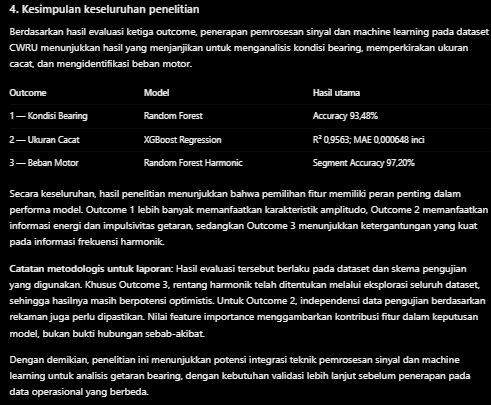

# Validasi

In [17]:

# ==================================================
# CELL 16 - FINAL PROJECT VALIDATION
# ==================================================

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("outputs")

required_files = {
    "Preprocessing": [
        "bearing_clean.csv",
        "metadata_rekaman.csv",
        "preprocessing_report.csv"
    ],
    "Signal Processing": [
        "bearing_filtered.csv"
    ],
    "Feature Engineering": [
        "bearing_features.csv",
        "segmentation_report.csv"
    ],
    "Outcome 1 - Random Forest": [
        "rf_cross_validation.csv",
        "rf_feature_importance.csv"
    ],
    "Outcome 2 - XGBoost": [
        "xgb_defect_predictions.csv",
        "xgb_feature_importance.csv"
    ],
    "Outcome 3 - Random Forest Harmonic": [
        "harmonic_rf_cross_validation.csv",
        "harmonic_rf_feature_importance.csv",
        "harmonic_rf_ablation_study.csv"
    ]
}

validation = []

for stage, filenames in required_files.items():
    for filename in filenames:
        path = OUTPUT_DIR / filename

        validation.append({
            "Tahapan": stage,
            "File": filename,
            "Status": (
                "Tersedia" if path.is_file()
                else "Tidak ditemukan"
            )
        })

validation_df = pd.DataFrame(validation)

print("FINAL PROJECT VALIDATION")
print("=" * 50)

display(validation_df)

print("\nTotal file diperiksa:", len(validation_df))
print(
    "File tersedia:",
    (validation_df["Status"] == "Tersedia").sum()
)
print(
    "File tidak ditemukan:",
    (validation_df["Status"] == "Tidak ditemukan").sum()
)

# Simpan laporan validasi
validation_df.to_csv(
    OUTPUT_DIR / "final_project_validation.csv",
    index=False
)


FINAL PROJECT VALIDATION


,Tahapan,File,Status
0,Preprocessing,bearing_clean.csv,Tersedia
1,Preprocessing,metadata_rekaman.csv,Tersedia
2,Preprocessing,preprocessing_report.csv,Tersedia
3,Signal Processing,bearing_filtered.csv,Tersedia
4,Feature Engineering,bearing_features.csv,Tersedia
5,Feature Engineering,segmentation_report.csv,Tersedia
6,Outcome 1 - Random Forest,rf_cross_validation.csv,Tersedia
7,Outcome 1 - Random Forest,rf_feature_importance.csv,Tersedia
8,Outcome 2 - XGBoost,xgb_defect_predictions.csv,Tersedia
9,Outcome 2 - XGBoost,xgb_feature_importance.csv,Tersedia



Total file diperiksa: 13
File tersedia: 13
File tidak ditemukan: 0


In [18]:

# ==========================================================
# CELL 17 - DATA INTEGRITY VALIDATION
# ==========================================================

import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("outputs")

# ----------------------------------------------------------
# 1. LOAD DATASET
# ----------------------------------------------------------

clean = pd.read_csv(
    OUTPUT_DIR / "bearing_clean.csv",
    usecols=[
        "source_file",
        "sample_index",
        "sampling_rate_hz",
        "vibration",
        "condition",
        "defect_size_inch",
        "motor_load_hp"
    ]
)

filtered = pd.read_csv(
    OUTPUT_DIR / "bearing_filtered.csv",
    usecols=[
        "source_file",
        "sample_index",
        "vibration_filtered"
    ]
)

features = pd.read_csv(
    OUTPUT_DIR / "bearing_features.csv"
)

harmonic = pd.read_csv(
    OUTPUT_DIR / "bearing_features_harmonic.csv"
)

# ----------------------------------------------------------
# 2. VALIDASI OTOMATIS
# ----------------------------------------------------------

checks = []

def add_check(name, passed, detail):
    checks.append({
        "Pemeriksaan": name,
        "Status": "PASS" if passed else "FAIL",
        "Keterangan": detail
    })

# Jumlah rekaman
for name, df in [
    ("Clean", clean),
    ("Filtered", filtered),
    ("Features", features),
    ("Harmonic", harmonic)
]:
    n = df["source_file"].nunique()

    add_check(
        f"Jumlah rekaman - {name}",
        n == 40,
        f"{n} dari 40 rekaman"
    )

# Sampling rate
sampling_rates = sorted(
    clean["sampling_rate_hz"].dropna().unique()
)

add_check(
    "Sampling rate 12.000 Hz",
    len(sampling_rates) == 1
    and sampling_rates[0] == 12000,
    f"Sampling rate: {sampling_rates}"
)

# Validitas amplitudo
for name, series in [
    ("Clean", clean["vibration"]),
    ("Filtered", filtered["vibration_filtered"])
]:
    valid = np.isfinite(series.to_numpy()).all()

    add_check(
        f"Amplitudo valid - {name}",
        valid,
        "Tidak ada NaN/Inf" if valid else "Ada NaN/Inf"
    )

# Duplikasi identitas sampel
for name, df in [
    ("Clean", clean),
    ("Filtered", filtered)
]:
    duplicates = df.duplicated(
        subset=["source_file", "sample_index"]
    ).sum()

    add_check(
        f"Duplikasi sampel - {name}",
        duplicates == 0,
        f"{duplicates} duplikasi"
    )

# Kesesuaian jumlah baris
add_check(
    "Jumlah sampel clean vs filtered",
    len(clean) == len(filtered),
    f"Clean={len(clean)}, Filtered={len(filtered)}"
)

# Kesesuaian identitas sampel
clean_ids = pd.MultiIndex.from_frame(
    clean[["source_file", "sample_index"]]
)
filtered_ids = pd.MultiIndex.from_frame(
    filtered[["source_file", "sample_index"]]
)

same_ids = (
    len(clean_ids) == len(filtered_ids)
    and clean_ids.difference(filtered_ids).empty
    and filtered_ids.difference(clean_ids).empty
)

add_check(
    "Identitas sampel clean vs filtered",
    same_ids,
    "Seluruh identitas cocok"
    if same_ids else "Ada identitas berbeda"
)

# Validitas label pada data clean
allowed_conditions = {
    "Normal", "Inner Race", "Ball Fault", "Outer Race"
}

add_check(
    "Label kondisi bearing",
    set(clean["condition"].dropna().unique())
    == allowed_conditions
    and clean["condition"].notna().all(),
    str(clean["condition"].value_counts().to_dict())
)

add_check(
    "Label beban motor",
    set(clean["motor_load_hp"].dropna().unique())
    == {0, 1, 2, 3}
    and clean["motor_load_hp"].notna().all(),
    str(clean["motor_load_hp"].value_counts().to_dict())
)

# Normal tidak memiliki ukuran cacat;
# rekaman fault harus memiliki salah satu ukuran yang valid
normal_mask = clean["condition"] == "Normal"
fault_mask = ~normal_mask

valid_defect = (
    clean.loc[normal_mask, "defect_size_inch"].isna().all()
    and clean.loc[fault_mask, "defect_size_inch"]
        .isin([0.007, 0.014, 0.021]).all()
)

add_check(
    "Validitas ukuran cacat",
    valid_defect,
    "Normal=NaN; Fault=0.007/0.014/0.021 inch"
)

# ----------------------------------------------------------
# 3. VALIDASI FEATURE ENGINEERING
# ----------------------------------------------------------

feature_columns = [
    "mean", "std", "rms", "skewness",
    "kurtosis", "peak_to_peak", "peak_amplitude",
    "crest_factor", "dominant_frequency",
    "spectral_centroid", "spectral_bandwidth",
    "spectral_entropy", "total_spectral_power",
    "band_power_low", "band_power_mid",
    "band_power_high"
]

missing_features = [
    c for c in feature_columns
    if c not in features.columns
]

add_check(
    "Kelengkapan 16 fitur",
    len(missing_features) == 0,
    f"Fitur hilang: {missing_features}"
)

if not missing_features:
    finite_features = np.isfinite(
        features[feature_columns].to_numpy()
    ).all()

    add_check(
        "Nilai fitur valid",
        finite_features,
        "Seluruh fitur finite"
        if finite_features else "Ada NaN/Inf"
    )

harmonic_columns = [
    "fundamental_frequency",
    "fundamental_power",
    "harmonic_2_frequency",
    "harmonic_2_power",
    "harmonic_3_frequency",
    "harmonic_3_power"
]

missing_harmonic = [
    c for c in harmonic_columns
    if c not in harmonic.columns
]

add_check(
    "Kelengkapan 6 fitur harmonik",
    len(missing_harmonic) == 0,
    f"Fitur hilang: {missing_harmonic}"
)

if not missing_harmonic:
    valid_harmonic = np.isfinite(
        harmonic[harmonic_columns].to_numpy()
    ).all()

    add_check(
        "Nilai harmonik valid",
        valid_harmonic,
        "Seluruh fitur finite"
        if valid_harmonic else "Ada NaN/Inf"
    )

# ----------------------------------------------------------
# 4. HASIL VALIDASI
# ----------------------------------------------------------

integrity_df = pd.DataFrame(checks)

print("FINAL DATA INTEGRITY VALIDATION")
print("=" * 55)

display(integrity_df)

passed = (integrity_df["Status"] == "PASS").sum()
failed = (integrity_df["Status"] == "FAIL").sum()

print(f"\nPASS : {passed}")
print(f"FAIL : {failed}")

integrity_df.to_csv(
    OUTPUT_DIR / "final_data_integrity_validation.csv",
    index=False
)

if failed == 0:
    print("\nSELURUH PEMERIKSAAN INTEGRITAS BERHASIL!")
else:
    print("\nPERHATIAN: Ada pemeriksaan yang perlu ditinjau.")


FINAL DATA INTEGRITY VALIDATION


,Pemeriksaan,Status,Keterangan
0,Jumlah rekaman - Clean,PASS,40 dari 40 rekaman
1,Jumlah rekaman - Filtered,PASS,40 dari 40 rekaman
2,Jumlah rekaman - Features,PASS,40 dari 40 rekaman
3,Jumlah rekaman - Harmonic,PASS,40 dari 40 rekaman
4,Sampling rate 12.000 Hz,PASS,Sampling rate: [np.int64(12000)]
5,Amplitudo valid - Clean,PASS,Tidak ada NaN/Inf
6,Amplitudo valid - Filtered,PASS,Tidak ada NaN/Inf
7,Duplikasi sampel - Clean,PASS,0 duplikasi
8,Duplikasi sampel - Filtered,PASS,0 duplikasi
9,Jumlah sampel clean vs filtered,PASS,"Clean=4815787, Filtered=4815787"



PASS : 18
FAIL : 0

SELURUH PEMERIKSAAN INTEGRITAS BERHASIL!


In [19]:

# ==========================================================
# CELL 18 - MODEL EVALUATION INTEGRITY
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ----------------------------------------------------------
# 1. LOAD HASIL EVALUASI
# ----------------------------------------------------------

rf_cv = pd.read_csv(
    OUTPUT_DIR / "rf_cross_validation.csv"
)

xgb_pred = pd.read_csv(
    OUTPUT_DIR / "xgb_defect_predictions.csv"
)

harmonic_cv = pd.read_csv(
    OUTPUT_DIR / "harmonic_rf_cross_validation.csv"
)

checks = []

def add_check(name, passed, detail):
    checks.append({
        "Pemeriksaan": name,
        "Status": "PASS" if passed else "FAIL",
        "Keterangan": detail
    })

# ----------------------------------------------------------
# 2. OUTCOME 1 - RANDOM FOREST
# ----------------------------------------------------------

rf_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

rf_complete = all(
    col in rf_cv.columns for col in rf_metrics
)

add_check(
    "Outcome 1 - Kelengkapan metrik",
    rf_complete,
    f"Kolom tersedia: {rf_cv.columns.tolist()}"
)

if rf_complete:
    rf_values = rf_cv[rf_metrics].to_numpy(
        dtype=float
    )

    add_check(
        "Outcome 1 - Rentang metrik",
        np.isfinite(rf_values).all()
        and ((rf_values >= 0) & (rf_values <= 1)).all(),
        "Seluruh metrik harus berada pada rentang 0-1"
    )

    add_check(
        "Outcome 1 - Jumlah fold",
        len(rf_cv) == 4,
        f"{len(rf_cv)} fold"
    )

# ----------------------------------------------------------
# 3. OUTCOME 2 - XGBOOST REGRESSION
# ----------------------------------------------------------

prediction_complete = {
    "Actual", "Predicted"
}.issubset(xgb_pred.columns)

add_check(
    "Outcome 2 - Kolom prediksi",
    prediction_complete,
    f"Kolom tersedia: {xgb_pred.columns.tolist()}"
)

if prediction_complete:

    actual = xgb_pred["Actual"].to_numpy(
        dtype=float
    )

    predicted = xgb_pred["Predicted"].to_numpy(
        dtype=float
    )

    valid_predictions = (
        len(actual) > 1
        and np.isfinite(actual).all()
        and np.isfinite(predicted).all()
        and np.unique(actual).size > 1
    )

    add_check(
        "Outcome 2 - Nilai prediksi valid",
        valid_predictions,
        f"Jumlah prediksi: {len(actual)}"
    )

    if valid_predictions:

        mae = mean_absolute_error(
            actual, predicted
        )

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        r2 = r2_score(actual, predicted)

        add_check(
            "Outcome 2 - Konsistensi error",
            rmse + 1e-12 >= mae,
            f"MAE={mae:.6f}, RMSE={rmse:.6f}"
        )

        add_check(
            "Outcome 2 - R2 finite",
            np.isfinite(r2),
            f"R2={r2:.6f}"
        )

        valid_sizes = np.isin(
            np.round(actual, 6),
            [0.007, 0.014, 0.021]
        ).all()

        add_check(
            "Outcome 2 - Ukuran cacat aktual",
            valid_sizes,
            "Target: 0.007, 0.014, 0.021 inch"
        )

# ----------------------------------------------------------
# 4. OUTCOME 3 - RANDOM FOREST HARMONIC
# ----------------------------------------------------------

harmonic_metrics = [
    "Segment Accuracy",
    "Segment Macro F1",
    "Recording Accuracy",
    "Recording Macro F1"
]

harmonic_complete = all(
    col in harmonic_cv.columns
    for col in harmonic_metrics
)

add_check(
    "Outcome 3 - Kelengkapan metrik",
    harmonic_complete,
    f"Kolom tersedia: {harmonic_cv.columns.tolist()}"
)

if harmonic_complete:

    harmonic_values = harmonic_cv[
        harmonic_metrics
    ].to_numpy(dtype=float)

    add_check(
        "Outcome 3 - Rentang metrik",
        np.isfinite(harmonic_values).all()
        and (
            (harmonic_values >= 0)
            & (harmonic_values <= 1)
        ).all(),
        "Seluruh metrik harus berada pada rentang 0-1"
    )

    add_check(
        "Outcome 3 - Jumlah fold",
        len(harmonic_cv) == 4,
        f"{len(harmonic_cv)} fold"
    )

# ----------------------------------------------------------
# 5. RINGKASAN VALIDASI
# ----------------------------------------------------------

evaluation_integrity = pd.DataFrame(checks)

print("MODEL EVALUATION INTEGRITY")
print("=" * 55)

display(evaluation_integrity)

passed = (
    evaluation_integrity["Status"] == "PASS"
).sum()

failed = (
    evaluation_integrity["Status"] == "FAIL"
).sum()

print(f"\nPASS : {passed}")
print(f"FAIL : {failed}")

# Simpan laporan
evaluation_integrity.to_csv(
    OUTPUT_DIR / "final_model_evaluation_integrity.csv",
    index=False
)

if failed == 0:
    print(
        "\nSeluruh pemeriksaan numerik evaluasi berhasil!"
    )
else:
    print(
        "\nAda pemeriksaan evaluasi yang perlu ditinjau."
    )


MODEL EVALUATION INTEGRITY


,Pemeriksaan,Status,Keterangan
0,Outcome 1 - Kelengkapan metrik,PASS,"Kolom tersedia: ['Fold', 'Accuracy', 'Precisio..."
1,Outcome 1 - Rentang metrik,PASS,Seluruh metrik harus berada pada rentang 0-1
2,Outcome 1 - Jumlah fold,PASS,4 fold
3,Outcome 2 - Kolom prediksi,PASS,"Kolom tersedia: ['Actual', 'Predicted', 'Absol..."
4,Outcome 2 - Nilai prediksi valid,PASS,Jumlah prediksi: 909
5,Outcome 2 - Konsistensi error,PASS,"MAE=0.000648, RMSE=0.001195"
6,Outcome 2 - R2 finite,PASS,R2=0.956253
7,Outcome 2 - Ukuran cacat aktual,PASS,"Target: 0.007, 0.014, 0.021 inch"
8,Outcome 3 - Kelengkapan metrik,PASS,"Kolom tersedia: ['Fold', 'Train Recordings', '..."
9,Outcome 3 - Rentang metrik,PASS,Seluruh metrik harus berada pada rentang 0-1



PASS : 11
FAIL : 0

Seluruh pemeriksaan numerik evaluasi berhasil!


In [20]:

# ==========================================================
# CELL 19 - TRAIN TEST LEAKAGE AUDIT
# ==========================================================

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("outputs")

# File yang berpotensi menyimpan informasi split
files_to_check = {
    "Outcome 1 - Random Forest":
        "rf_cross_validation.csv",

    "Outcome 2 - XGBoost":
        "xgb_defect_predictions.csv",

    "Outcome 3 - Harmonic RF":
        "harmonic_rf_recording_results.csv"
}

results = []

def find_column(columns, candidates):
    lookup = {
        c.lower().strip(): c
        for c in columns
    }

    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]

    return None

for outcome, filename in files_to_check.items():

    path = OUTPUT_DIR / filename

    if not path.exists():
        results.append({
            "Outcome": outcome,
            "Status": "BELUM TERVERIFIKASI",
            "Keterangan": f"{filename} tidak ditemukan"
        })
        continue

    df = pd.read_csv(path)

    # Deteksi kolom identitas rekaman dan split
    source_col = find_column(
        df.columns,
        ["source_file", "recording", "recording_id"]
    )

    split_col = find_column(
        df.columns,
        ["split", "dataset_split", "set", "partition"]
    )

    fold_col = find_column(
        df.columns,
        ["fold", "cv_fold"]
    )

    if source_col is None or split_col is None:
        results.append({
            "Outcome": outcome,
            "Status": "BELUM TERVERIFIKASI",
            "Keterangan": (
                f"Kolom tersedia: {df.columns.tolist()}. "
                "Perlu memeriksa kode pembagian data."
            )
        })
        continue

    # Normalisasi nama kelompok
    split_values = (
        df[split_col]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    train_mask = split_values.isin(
        ["train", "training"]
    )

    test_mask = split_values.isin(
        ["test", "testing", "validation", "val"]
    )

    if not train_mask.any() or not test_mask.any():
        results.append({
            "Outcome": outcome,
            "Status": "BELUM TERVERIFIKASI",
            "Keterangan": "Label train/test tidak lengkap"
        })
        continue

    # Untuk CV, pemeriksaan dilakukan per fold
    if fold_col is not None:
        groups = df.groupby(fold_col)
    else:
        groups = [("Holdout", df)]

    total_overlap = 0
    checked_groups = 0

    for fold_name, group in groups:

        labels = (
            group[split_col]
            .astype(str)
            .str.lower()
            .str.strip()
        )

        train_files = set(
            group.loc[
                labels.isin(["train", "training"]),
                source_col
            ].dropna()
        )

        test_files = set(
            group.loc[
                labels.isin(
                    ["test", "testing", "validation", "val"]
                ),
                source_col
            ].dropna()
        )

        if train_files and test_files:
            checked_groups += 1
            total_overlap += len(
                train_files.intersection(test_files)
            )

    if checked_groups == 0:
        status = "BELUM TERVERIFIKASI"
        detail = "Tidak ada fold dengan train dan test lengkap"

    elif total_overlap == 0:
        status = "PASS"
        detail = (
            f"{checked_groups} split diperiksa, "
            "tidak ada rekaman yang overlap"
        )

    else:
        status = "FAIL"
        detail = (
            f"Ditemukan {total_overlap} overlap "
            "identitas rekaman antar split"
        )

    results.append({
        "Outcome": outcome,
        "Status": status,
        "Keterangan": detail
    })

# ----------------------------------------------------------
# HASIL AUDIT
# ----------------------------------------------------------

leakage_audit = pd.DataFrame(results)

print("TRAIN-TEST LEAKAGE AUDIT")
print("=" * 60)

display(leakage_audit)

print("\nRingkasan:")
print(leakage_audit["Status"].value_counts())

leakage_audit.to_csv(
    OUTPUT_DIR / "final_leakage_audit.csv",
    index=False
)


TRAIN-TEST LEAKAGE AUDIT


,Outcome,Status,Keterangan
0,Outcome 1 - Random Forest,BELUM TERVERIFIKASI,"Kolom tersedia: ['Fold', 'Accuracy', 'Precisio..."
1,Outcome 2 - XGBoost,BELUM TERVERIFIKASI,"Kolom tersedia: ['Actual', 'Predicted', 'Absol..."
2,Outcome 3 - Harmonic RF,BELUM TERVERIFIKASI,"Kolom tersedia: ['source_file', 'actual', 'pre..."



Ringkasan:
Status
BELUM TERVERIFIKASI    3
Name: count, dtype: int64
